# 05 · Interpretabilidad con Grad-CAM

Grad-CAM explica al **modelo**, no al insecto: muestra qué regiones movieron la predicción, no qué rasgos distinguen a la especie.

`DatasetInsectos` guardó la caja de detección de YOLO-World de cada imagen (`auditoria.csv`; en Kaggle tiene que estar en el dataset adjunto), así que se puede **medir** qué fracción de la activación cae sobre el ejemplar. La comparación no es contra cero sino contra el área de la caja: si el insecto ocupa, digamos, la mitad del recorte, una atención repartida al azar daría ~0.5. Solo lo que exceda eso es evidencia de que el modelo mira al animal.

In [1]:
import os
import subprocess
import sys
from pathlib import Path

if Path("/kaggle").exists():
    from kaggle_secrets import UserSecretsClient

    CLON = "/tmp/InsectModeling"
    AYUDA = "!f() { echo username=x-access-token; echo password=$GITHUB_TOKEN; }; f"
    os.environ["GITHUB_TOKEN"] = UserSecretsClient().get_secret("GITHUB_TOKEN")
    if not Path(CLON).exists():
        subprocess.run(["git", "-c", f"credential.helper={AYUDA}", "clone",
                        "https://github.com/santiagoortizc/InsectModeling.git", CLON], check=True)
    sys.path.insert(0, CLON)
    os.chdir(CLON)
    print("clon en", CLON, "·", subprocess.run(
        ["git", "log", "-1", "--format=%h %s"], cwd=CLON,
        capture_output=True, text=True).stdout.strip())

In [2]:
import os
import sys
from pathlib import Path

ROOT = Path.cwd()
while not (ROOT / "corpus.json").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

print("Raíz del proyecto:", ROOT)

FIGURAS = ROOT / "outputs" / "gradcam"
FIGURAS.mkdir(parents=True, exist_ok=True)

Raíz del proyecto: /home/santiago/projects/proyecto_semillero/ModeladoInsectos


In [3]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

from scripts import corpus
from scripts import modelRegistry as registro
from scripts.architectures import capaFeatures, preprocessFn
from scripts.gradcam import (areaCaja, cajaEnRecorte, computeGradcam,
                             fraccionDentro, overlayHeatmap)
from scripts.vizStyle import (INK_MUTED, SERIE_1, SERIE_2, SERIE_3, applyStyle,
                              limpiarEje)

MUESTRA = 150       # imágenes de test para la parte cuantitativa
SEMILLA = 42

corpus.materializar()
clases = corpus.classNames()

auditoria = corpus.auditoria()
auditoria = auditoria[auditoria.split == "test"]
print(f"{len(auditoria)} imágenes de test con caja de detección")

2724 imágenes de test con caja de detección


## 1 · Los dos modelos a comparar

El estudiante es el que se despliega, así que sus explicaciones son las que el
usuario va a ver. El docente sirve de referencia: ¿el modelo más preciso mira
mejor evidencia, o solo aprovecha más capacidad?

In [4]:
MODELOS = {}
for rol, archivo in (("estudiante", "student.json"), ("docente", "teacher.json")):
    info = registro.readJson(registro.OUTPUTS_DIR / archivo)
    if info is None:
        print(f"Falta outputs/{archivo}")
        continue
    MODELOS[rol] = {
        "arquitectura": info["architecture"],
        "modelo": registro.modeloInferencia(info["run_id"]),
        "preprocess": preprocessFn(info["architecture"]),
        "f1": info["test_macro_f1"],
    }

pd.DataFrame([{
    "rol": rol, "arquitectura": m["arquitectura"],
    "macro_f1": round(m["f1"], 4),
    "resolucion_mapa": tuple(capaFeatures(m["modelo"]).shape[1:3]),
} for rol, m in MODELOS.items()])

/home/santiago/projects/proyecto_semillero/ModeladoInsectos/scripts/architectures.py:67: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = baseClass(weights="imagenet", include_top=False, input_tensor=tensor)


,rol,arquitectura,macro_f1,resolucion_mapa
0,estudiante,mobilenet_v2,0.9298,"(14, 14)"
1,docente,efficientnet_b3,0.9623,"(14, 14)"


## 2 · Panel cualitativo

Para cuatro clases al azar se toma la predicción correcta más confiada del estudiante, y
se explica **la clase predicha** en ambos modelos sobre la misma imagen.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


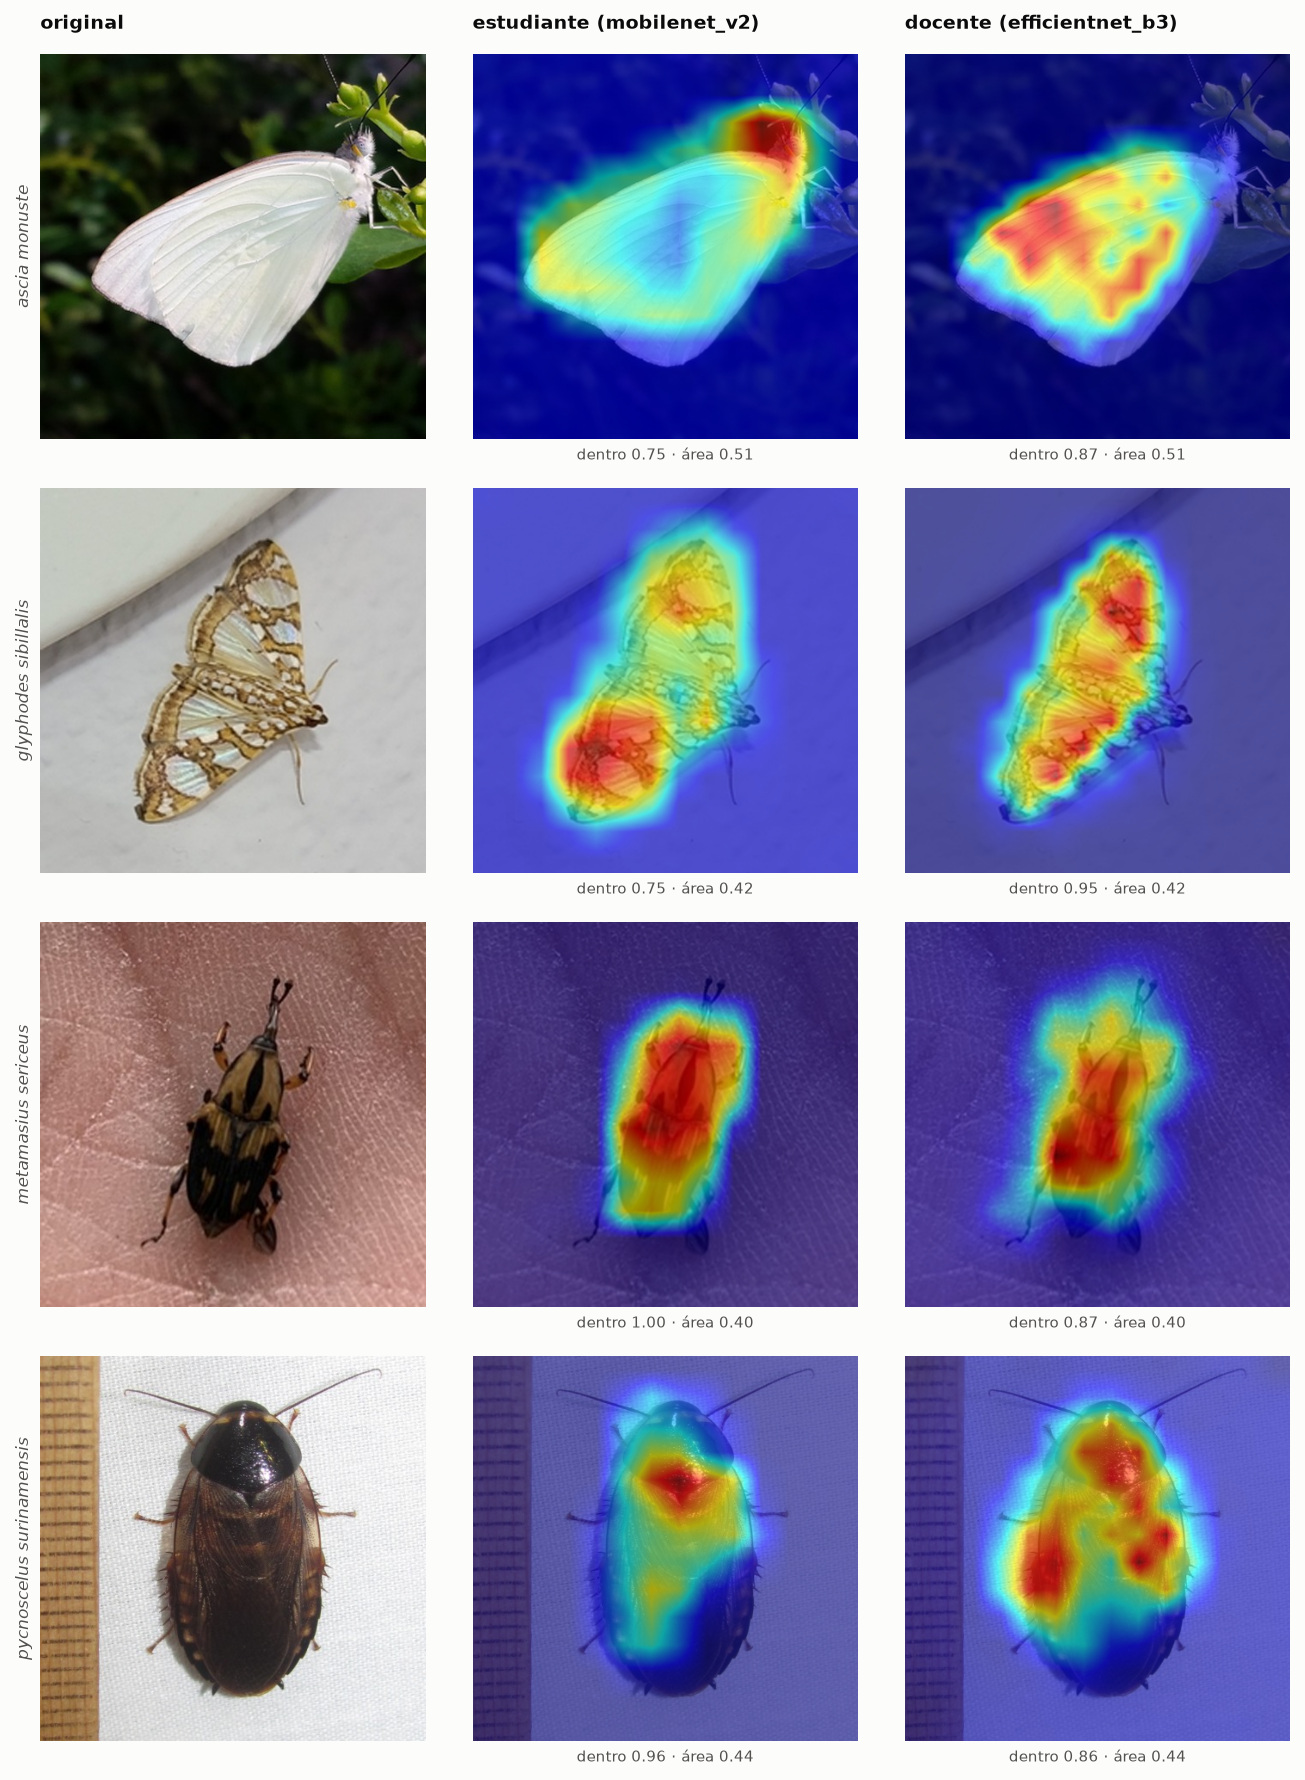

In [5]:
def rutaTest(fila):
    """Por la columna `clase`: en atta_spp el archivo lleva el nombre de la especie real."""
    return Path("dataset/test") / fila["clase"] / fila["archivo"]


def predecir(m, img):
    arr = np.asarray(img.convert("RGB").resize(
        (m["modelo"].input_shape[2], m["modelo"].input_shape[1])), dtype=np.float32)
    probs = m["modelo"].predict(m["preprocess"](arr[None]), verbose=0)[0]
    return int(np.argmax(probs)), float(np.max(probs))


rng = np.random.default_rng(SEMILLA)
especiesPanel = sorted(rng.choice(clases, 4, replace=False))

filas = []
for especie in especiesPanel:
    candidatas = auditoria[auditoria.clase == especie]
    mejor = None
    for _, fila in candidatas.iterrows():
        img = Image.open(rutaTest(fila))
        idx, conf = predecir(MODELOS["estudiante"], img)
        if clases[idx] == especie and (mejor is None or conf > mejor[1]):
            mejor = (fila, conf, img, idx)
    if mejor is None:   # sin acierto: se muestra el error más confiado
        fila = candidatas.iloc[0]
        img = Image.open(rutaTest(fila))
        idx, conf = predecir(MODELOS["estudiante"], img)
        mejor = (fila, conf, img, idx)
    filas.append((especie, *mejor))

applyStyle()
fig, ejes = plt.subplots(len(filas), 3, figsize=(9, 3 * len(filas)))
for f, (especie, fila, conf, img, idx) in enumerate(filas):
    caja = cajaEnRecorte(fila)
    ejes[f, 0].imshow(img)
    limpiarEje(ejes[f, 0])
    ejes[f, 0].set_ylabel(especie.replace("_", " "), fontsize=8, style="italic")
    if f == 0:
        ejes[f, 0].set_title("original", fontsize=9)
    for k, rol in enumerate(("estudiante", "docente"), start=1):
        m = MODELOS[rol]
        mapa = computeGradcam(m["modelo"], img, idx, m["preprocess"])
        ejes[f, k].imshow(overlayHeatmap(img, mapa))
        limpiarEje(ejes[f, k])
        ejes[f, k].set_xlabel(f"dentro {fraccionDentro(mapa, caja):.2f} · área {areaCaja(caja):.2f}",
                              fontsize=7)
        if f == 0:
            ejes[f, k].set_title(f"{rol} ({m['arquitectura']})", fontsize=9)
fig.tight_layout()
fig.savefig(FIGURAS / "panel_cualitativo.png", dpi=200, bbox_inches="tight")
plt.show()

## 3 · ¿Mira al ejemplar? La medición

Se calcula sobre una muestra del test. `dentro` es la fracción de activación
que cae en la caja; `area` es la misma fracción si la atención fuera uniforme.
La diferencia entre ambas es lo único que sostiene la afirmación "el modelo
mira al insecto".

In [6]:
muestra = auditoria.sample(min(MUESTRA, len(auditoria)), random_state=SEMILLA)

registros = []
for _, fila in muestra.iterrows():
    img = Image.open(rutaTest(fila))
    caja = cajaEnRecorte(fila)
    area = areaCaja(caja)
    if area <= 0:
        continue
    for rol, m in MODELOS.items():
        idx, conf = predecir(m, img)
        mapa = computeGradcam(m["modelo"], img, idx, m["preprocess"])
        registros.append({
            "rol": rol,
            "clase": fila["clase"],
            "acierto": clases[idx] == fila["clase"],
            "confianza": conf,
            "dentro": fraccionDentro(mapa, caja),
            "area": area,
        })

atencion = pd.DataFrame(registros).dropna(subset=["dentro"])
atencion["exceso"] = atencion["dentro"] - atencion["area"]

resumen = atencion.groupby("rol").agg(
    n=("dentro", "size"),
    dentro_media=("dentro", "mean"),
    area_media=("area", "mean"),
    exceso_medio=("exceso", "mean"),
    exceso_mediano=("exceso", "median"),
).round(4)
print(resumen.to_string())
print()
for rol, g in atencion.groupby("rol"):
    frac = (g["exceso"] > 0).mean()
    print(f"  {rol:11} concentra por encima del azar en {frac:.1%} de las imágenes")

              n  dentro_media  area_media  exceso_medio  exceso_mediano
rol                                                                    
docente     150        0.8817       0.526        0.3557          0.3686
estudiante  150        0.8546       0.526        0.3286          0.3303

  docente     concentra por encima del azar en 98.7% de las imágenes
  estudiante  concentra por encima del azar en 99.3% de las imágenes


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


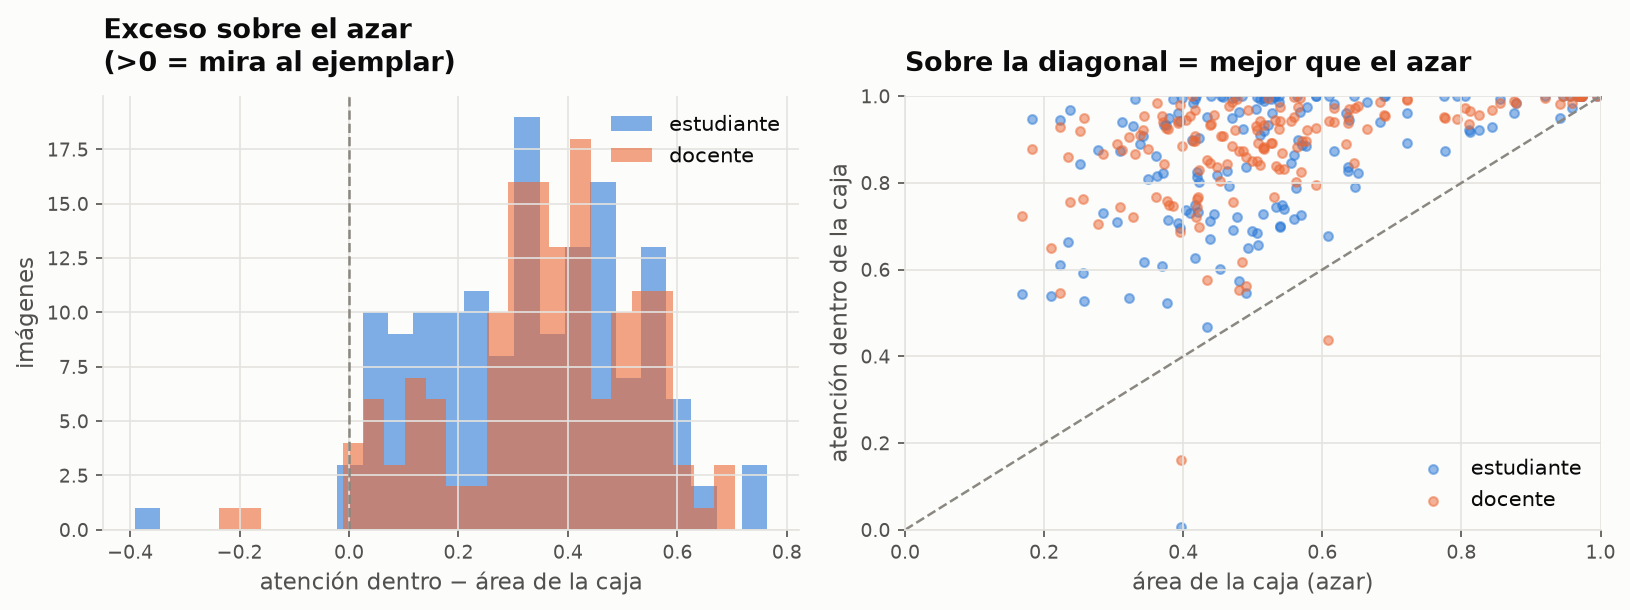

In [7]:
applyStyle()
fig, ejes = plt.subplots(1, 2, figsize=(11, 4.2))

for rol, color in (("estudiante", SERIE_1), ("docente", SERIE_2)):
    g = atencion[atencion["rol"] == rol]
    ejes[0].hist(g["exceso"], bins=25, alpha=0.6, color=color, label=rol)
ejes[0].axvline(0, color=INK_MUTED, linestyle="--", linewidth=1.2)
ejes[0].set(xlabel="atención dentro − área de la caja", ylabel="imágenes",
            title="Exceso sobre el azar\n(>0 = mira al ejemplar)")
ejes[0].legend()

for rol, color in (("estudiante", SERIE_1), ("docente", SERIE_2)):
    g = atencion[atencion["rol"] == rol]
    ejes[1].scatter(g["area"], g["dentro"], s=18, alpha=0.5, color=color, label=rol)
lim = [0, 1]
ejes[1].plot(lim, lim, color=INK_MUTED, linestyle="--", linewidth=1.2)
ejes[1].set(xlim=lim, ylim=lim, xlabel="área de la caja (azar)",
            ylabel="atención dentro de la caja",
            title="Sobre la diagonal = mejor que el azar")
ejes[1].legend(loc="lower right")

fig.tight_layout()
fig.savefig(FIGURAS / "atencion_vs_azar.png", dpi=200, bbox_inches="tight")
plt.show()

atencion.to_csv(FIGURAS / "atencion.csv", index=False)

## 4 · ¿Mira peor cuando se equivoca?

Si la atención cae fuera del ejemplar justo en los errores, Grad-CAM sirve como
señal de baja confiabilidad y no solo como ilustración.

In [8]:
porAcierto = atencion.groupby(["rol", "acierto"]).agg(
    n=("exceso", "size"),
    exceso_medio=("exceso", "mean"),
    confianza_media=("confianza", "mean"),
).round(4)
print(porAcierto.to_string())

print()
for rol, g in atencion.groupby("rol"):
    ok, mal = g[g["acierto"]]["exceso"], g[~g["acierto"]]["exceso"]
    if len(mal) >= 5:
        print(f"  {rol:11} exceso en aciertos {ok.mean():+.4f} vs errores {mal.mean():+.4f} "
              f"(diferencia {ok.mean() - mal.mean():+.4f}, n_errores={len(mal)})")
    else:
        print(f"  {rol:11} solo {len(mal)} errores en la muestra: insuficiente para comparar")

                      n  exceso_medio  confianza_media
rol        acierto                                    
docente    False      5        0.2584           0.7764
           True     145        0.3590           0.9905
estudiante False      7        0.1143           0.7157
           True     143        0.3391           0.9876

  docente     exceso en aciertos +0.3590 vs errores +0.2584 (diferencia +0.1006, n_errores=5)
  estudiante  exceso en aciertos +0.3391 vs errores +0.1143 (diferencia +0.2248, n_errores=7)


## 5 · Confusiones intra-género

Pares del mismo género (*Dione*, *Diabrotica*, *Erinnyis*, *Leptoglossus*). Para cada par se toma
una imagen que el estudiante **sí** confundió en test y se explican las dos
clases: la real y la que eligió.

In [9]:
info = registro.readJson(registro.OUTPUTS_DIR / "student.json")
metricas = registro.loadRunMetrics(info["run_id"])["splits"]["test"]
matriz = np.array(metricas["confusion_matrix"])
nombres = metricas["class_names"]

pares = [
    {"real": nombres[i], "predicha": nombres[j], "casos": int(matriz[i][j])}
    for i in range(len(nombres)) for j in range(len(nombres))
    if i != j and matriz[i][j] > 0 and nombres[i].split("_")[0] == nombres[j].split("_")[0]
]
pares = sorted(pares, key=lambda p: -p["casos"])[:3]
pd.DataFrame(pares)

,real,predicha,casos
0,erinnyis_ello,erinnyis_alope,9
1,diabrotica_decempunctata,diabrotica_speciosa,7
2,dione_glycera,dione_juno,4


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


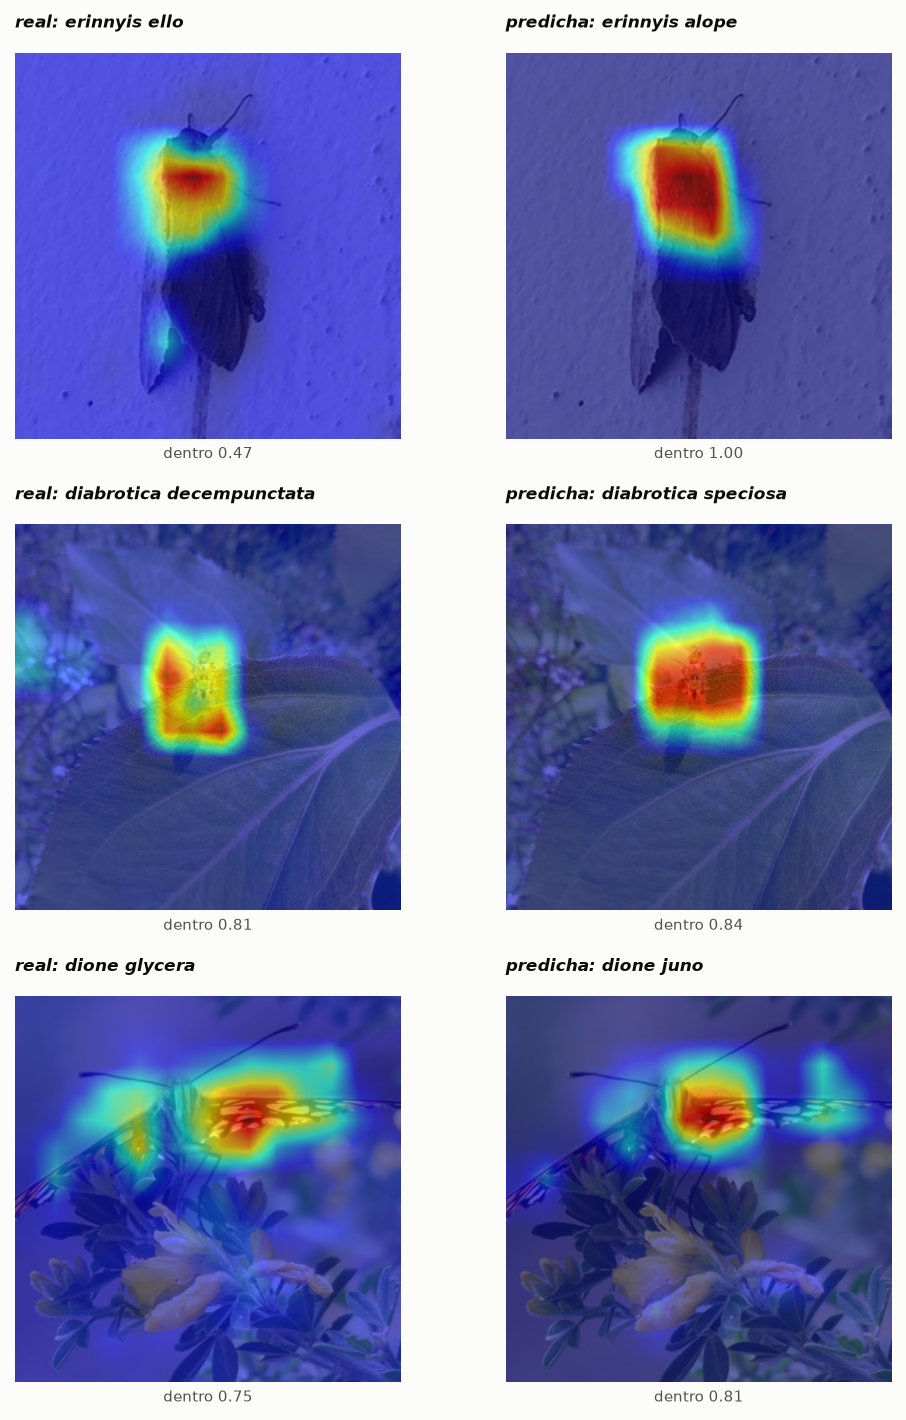

figuras en /home/santiago/projects/proyecto_semillero/ModeladoInsectos/outputs/gradcam


In [10]:
# mismo orden que evalStats.evaluar: clases y archivos ordenados, como image_dataset_from_directory
archivosTest = [(clase, archivo) for clase in nombres
                for archivo in sorted(p.name for p in (Path("dataset/test") / clase).iterdir())]
yReal, yPred = np.array(metricas["y_true"]), np.array(metricas["y_pred"])
cajas = auditoria.set_index("archivo")

applyStyle()
m = MODELOS["estudiante"]
fig, ejes = plt.subplots(len(pares), 2, figsize=(7, 3.2 * len(pares)))
ejes = np.atleast_2d(ejes)

for f, par in enumerate(pares):
    i = int(np.flatnonzero((yReal == nombres.index(par["real"]))
                           & (yPred == nombres.index(par["predicha"])))[0])
    clase, archivo = archivosTest[i]
    img = Image.open(Path("dataset/test") / clase / archivo)
    caja = cajaEnRecorte(cajas.loc[archivo])
    for k, (etiqueta, especie) in enumerate((("real", par["real"]), ("predicha", par["predicha"]))):
        mapa = computeGradcam(m["modelo"], img, clases.index(especie), m["preprocess"])
        ejes[f, k].imshow(overlayHeatmap(img, mapa))
        limpiarEje(ejes[f, k])
        ejes[f, k].set_title(f"{etiqueta}: {especie.replace('_', ' ')}", fontsize=8, style="italic")
        ejes[f, k].set_xlabel(f"dentro {fraccionDentro(mapa, caja):.2f}", fontsize=7)
fig.tight_layout()
fig.savefig(FIGURAS / "confusiones_genero.png", dpi=200, bbox_inches="tight")
plt.show()

from scripts.kaggle import publicarArchivos
if Path("/kaggle").exists():
    publicarArchivos("Add Grad-CAM figures", "outputs/gradcam")
print("figuras en", FIGURAS)

## Lo que esto sí y no permite afirmar

**Sí**: cuánta de la activación cae sobre el ejemplar frente a lo que daría el
azar, medido sobre una muestra del test y no sobre una imagen elegida a mano.

**No**: que las regiones resaltadas sean los rasgos taxonómicos que usa un
especialista. La caja de YOLO-World acota al animal completo, no a la venación
ni a las antenas o las patas, así que "dentro de la caja" no equivale a "mirando el rasgo
diagnóstico".

**Límite de resolución**: los mapas salen de la última capa convolucional, de
14x14 para una entrada de 448x448. Cada celda cubre 32 píxeles, así que la
localización es gruesa por construcción — Grad-CAM++ o capas intermedias darían
más detalle.